In [1]:
import pandas as pd

# Load the analysis-ready dataset
flights = pd.read_csv("data/cleaned/analysis_ready_flights.csv")

# Check the dataset dimensions
print("Dataset shape:", flights.shape)

# Check the column names
print(flights.columns.tolist())

Dataset shape: (327346, 34)
['year', 'month', 'day', 'dep_time', 'sched_dep_time', 'dep_delay', 'arr_time', 'sched_arr_time', 'arr_delay', 'carrier', 'flight', 'tailnum', 'origin', 'dest', 'air_time', 'distance', 'hour', 'minute', 'time_hour', 'season', 'scheduled_hour', 'year_weather', 'month_weather', 'day_weather', 'hour_weather', 'temp', 'dewp', 'humid', 'wind_dir', 'wind_speed', 'wind_gust', 'precip', 'pressure', 'visib']


In [2]:
# Check missing values in the Model 1 variables
model1_variables = [
    "arr_delay",
    "season",
    "carrier",
    "scheduled_hour",
    "distance",
    "origin"
]

print(flights[model1_variables].isna().sum())

# Check the categories in each categorical variable
print("\nSeason categories:")
print(flights["season"].value_counts())

print("\nAirlines:")
print(flights["carrier"].nunique())
print(flights["carrier"].value_counts())

print("\nOrigin airports:")
print(flights["origin"].value_counts())

arr_delay         0
season            0
carrier           0
scheduled_hour    0
distance          0
origin            0
dtype: int64

Season categories:
season
Summer    84124
Spring    83594
Fall      82599
Winter    77029
Name: count, dtype: int64

Airlines:
16
carrier
UA    57782
B6    54049
EV    51108
DL    47658
AA    31947
MQ    25037
US    19831
9E    17294
WN    12044
VX     5116
FL     3175
AS      709
F9      681
YV      544
HA      342
OO       29
Name: count, dtype: int64

Origin airports:
origin
EWR    117127
JFK    109079
LGA    101140
Name: count, dtype: int64


In [3]:
# Create a separate dataset for Model 1
model1_data = flights[
    ["arr_delay", "season", "carrier", "scheduled_hour", "distance", "origin"]
].copy()

# Set the reference categories
model1_data["season"] = pd.Categorical(
    model1_data["season"],
    categories=["Winter", "Spring", "Summer", "Fall"]
)

model1_data["carrier"] = pd.Categorical(
    model1_data["carrier"],
    categories=["AA", "AS", "B6", "DL", "EV", "F9", "FL", "HA",
                "MQ", "OO", "UA", "US", "VX", "WN", "YV", "9E"]
)

model1_data["origin"] = pd.Categorical(
    model1_data["origin"],
    categories=["JFK", "LGA", "EWR"]
)

# Convert categorical variables into dummy variables
model1_data = pd.get_dummies(
    model1_data,
    columns=["season", "carrier", "origin"],
    drop_first=True,
    dtype=int
)

# Check the prepared dataset
print("Model 1 dataset shape:", model1_data.shape)
print(model1_data.head())
print("\nData types:")
print(model1_data.dtypes)

Model 1 dataset shape: (327346, 23)
   arr_delay  scheduled_hour  distance  season_Spring  season_Summer  \
0       11.0               5      1400              0              0   
1       20.0               5      1416              0              0   
2       33.0               5      1089              0              0   
3      -18.0               5      1576              0              0   
4      -25.0               6       762              0              0   

   season_Fall  carrier_AS  carrier_B6  carrier_DL  carrier_EV  ...  \
0            0           0           0           0           0  ...   
1            0           0           0           0           0  ...   
2            0           0           0           0           0  ...   
3            0           0           1           0           0  ...   
4            0           0           0           1           0  ...   

   carrier_MQ  carrier_OO  carrier_UA  carrier_US  carrier_VX  carrier_WN  \
0           0           0  

In [5]:
%pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 2.8 MB/s  0:00:046m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 30.3 MB/s  0:00:016m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [statsmodels] [statsmodels]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
import statsmodels.api as sm

y = model1_data["arr_delay"]
X = model1_data.drop(columns=["arr_delay"])
X = sm.add_constant(X)

model1 = sm.OLS(y, X).fit()

print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:              arr_delay   R-squared:                       0.058
Model:                            OLS   Adj. R-squared:                  0.058
Method:                 Least Squares   F-statistic:                     918.8
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:13:19   Log-Likelihood:            -1.6981e+06
No. Observations:              327346   AIC:                         3.396e+06
Df Residuals:                  327323   BIC:                         3.396e+06
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const            -17.4022      0.427    -40.

The model includes 327,346 flights and examines how season, airline, scheduled departure hour, flight distance, and origin airport relate to arrival delays. The model explains 5.8% of the variation in arrival delays. The results show some differences across seasons, airlines, and airports. Further diagnostics are needed to check the model's reliability.

In [ ]:
The following diagnostics evaluate potential multicollinearity among predictors 
and assess the assumptions of the regression model.

In [7]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()

vif_data["Variable"] = X.columns
vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif_data.sort_values("VIF", ascending=False))

          Variable       VIF
9       carrier_EV  2.953432
15      carrier_UA  2.894629
22      origin_EWR  2.625609
7       carrier_B6  2.478384
8       carrier_DL  2.135957
21      origin_LGA  1.940076
13      carrier_MQ  1.773154
2         distance  1.700524
20      carrier_9E  1.671396
16      carrier_US  1.633225
4    season_Summer  1.555593
3    season_Spring  1.553203
5      season_Fall  1.551934
18      carrier_WN  1.397410
17      carrier_VX  1.210033
11      carrier_FL  1.113943
12      carrier_HA  1.050099
6       carrier_AS  1.042473
10      carrier_F9  1.025024
19      carrier_YV  1.022200
1   scheduled_hour  1.017129
14      carrier_OO  1.001282
0            const  1.000000


The VIF results were all below 5, which means the variables in the model are not too closely related to each other. Based on these results, we kept all the variables in Model 1.

In [9]:
%pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 19.0 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 23.9 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 22.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 25.8 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


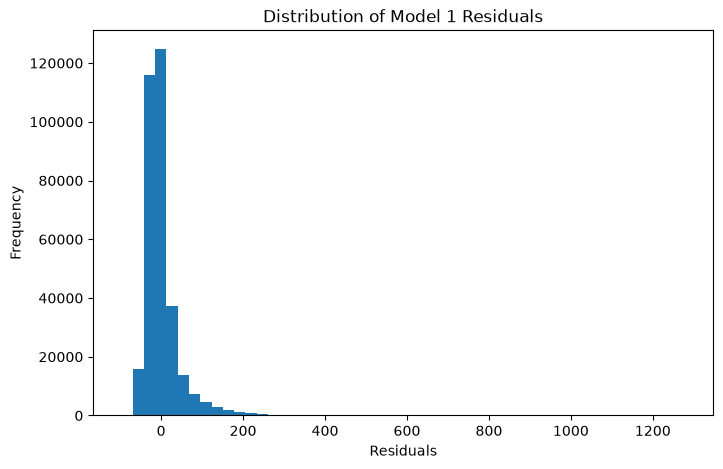

In [10]:
import matplotlib.pyplot as plt

residuals = model1.resid

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=50)
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Model 1 Residuals")
plt.show()